<a href="https://colab.research.google.com/github/krishnanpatil1212/AutoValue-AI/blob/main/Used_Car_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Column names of our dataset
columns = [
    'symboling', 'normalized-losses', 'make',
    'fuel-type', 'aspiration', 'num-of-doors',
    'body-style', 'drive-wheels', 'engine-location',
    'wheel-base', 'length', 'width', 'height',
    'curb-weight', 'engine-type', 'num-of-cylinders',
    'engine-size', 'fuel-system', 'bore', 'stroke',
    'compression-ratio', 'horsepower', 'peak-rpm',
    'city-mpg', 'highway-mpg', 'price'
]

# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"

# Load dataset
df = pd.read_csv(url, names=columns, na_values="?")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0
3,2,164.0,audi,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0
4,2,164.0,audi,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0


In [4]:
df.head(10)   # First 10 rows
df.tail()     # Last 5 rows

,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
200,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,23,28,16845.0
201,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,8.7,160.0,5300.0,19,25,19045.0
202,-1,95.0,volvo,gas,std,four,sedan,rwd,front,109.1,...,173,mpfi,3.58,2.87,8.8,134.0,5500.0,18,23,21485.0
203,-1,95.0,volvo,diesel,turbo,four,sedan,rwd,front,109.1,...,145,idi,3.01,3.40,23.0,106.0,4800.0,26,27,22470.0
204,-1,95.0,volvo,gas,turbo,four,sedan,rwd,front,109.1,...,141,mpfi,3.78,3.15,9.5,114.0,5400.0,19,25,22625.0


In [5]:
df.shape

(205, 26)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          205 non-null    int64  
 1   normalized-losses  164 non-null    float64
 2   make               205 non-null    object 
 3   fuel-type          205 non-null    object 
 4   aspiration         205 non-null    object 
 5   num-of-doors       203 non-null    object 
 6   body-style         205 non-null    object 
 7   drive-wheels       205 non-null    object 
 8   engine-location    205 non-null    object 
 9   wheel-base         205 non-null    float64
 10  length             205 non-null    float64
 11  width              205 non-null    float64
 12  height             205 non-null    float64
 13  curb-weight        205 non-null    int64  
 14  engine-type        205 non-null    object 
 15  num-of-cylinders   205 non-null    object 
 16  engine-size        205 non

In [7]:
df.isnull().sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
aspiration,0
num-of-doors,2
body-style,0
drive-wheels,0
engine-location,0
wheel-base,0


In [8]:
df.isnull().sum().sort_values(ascending=False)

,0
normalized-losses,41
stroke,4
price,4
bore,4
horsepower,2
peak-rpm,2
num-of-doors,2
symboling,0
fuel-type,0
make,0


In [9]:
df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
count,205.000000,164.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,201.000000,201.000000,205.000000,203.000000,203.000000,205.000000,205.000000,201.000000
mean,0.834146,122.000000,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329751,3.255423,10.142537,104.256158,5125.369458,25.219512,30.751220,13207.129353
std,1.245307,35.442168,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.273539,0.316717,3.972040,39.714369,479.334560,6.542142,6.886443,7947.066342
min,-2.000000,65.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,0.000000,94.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000
50%,1.000000,115.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,2.000000,150.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.590000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000
max,3.000000,256.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [10]:
df['price'].mean()

np.float64(13207.129353233831)

In [11]:
df['price'].max()

45400.0

In [12]:
df['price'].min()

5118.0

In [13]:
df.isnull().sum()

,0
symboling,0
normalized-losses,41
make,0
fuel-type,0
aspiration,0
num-of-doors,2
body-style,0
drive-wheels,0
engine-location,0
wheel-base,0


In [14]:
df.dtypes

,0
symboling,int64
normalized-losses,float64
make,object
fuel-type,object
aspiration,object
num-of-doors,object
body-style,object
drive-wheels,object
engine-location,object
wheel-base,float64


In [15]:
df_clean=df.copy()

In [16]:
df_clean=df_clean.dropna(subset=['price'])

In [17]:
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns.drop('price')

df_clean[numeric_cols] = df_clean[numeric_cols].fillna(
    df_clean[numeric_cols].mean()
)

In [18]:
categorical_cols = df_clean.select_dtypes(
    include='object'
).columns

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].mode()[0]
    )

In [19]:
df_clean.isnull().sum()

,0
symboling,0
normalized-losses,0
make,0
fuel-type,0
aspiration,0
num-of-doors,0
body-style,0
drive-wheels,0
engine-location,0
wheel-base,0


In [20]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (205, 26)
Cleaned shape: (201, 26)


In [21]:
df_clean.dtypes

,0
symboling,int64
normalized-losses,float64
make,object
fuel-type,object
aspiration,object
num-of-doors,object
body-style,object
drive-wheels,object
engine-location,object
wheel-base,float64


In [22]:
df_clean['horsepower'] = pd.to_numeric(
    df_clean['horsepower'], errors='coerce'
)

df_clean['price'] = pd.to_numeric(
    df_clean['price'], errors='coerce'
)

In [23]:
df_clean[['horsepower', 'price']].dtypes

,0
horsepower,float64
price,float64


In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

columns_to_scale = [
    'horsepower',
    'engine-size',
    'highway-mpg'
]

df_scaled = df_clean.copy()

df_scaled[columns_to_scale] = scaler.fit_transform(
    df_clean[columns_to_scale]
)

df_scaled[columns_to_scale].head()

,horsepower,engine-size,highway-mpg
0,0.294393,0.260377,0.289474
1,0.294393,0.260377,0.289474
2,0.495327,0.343396,0.263158
3,0.252336,0.181132,0.368421
4,0.313084,0.283019,0.157895


In [25]:
print("Original:")
print(df_clean[columns_to_scale].head())

print("Normalized:")
print(df_scaled[columns_to_scale].head())

Original:
   horsepower  engine-size  highway-mpg
0       111.0          130           27
1       111.0          130           27
2       154.0          152           26
3       102.0          109           30
4       115.0          136           22
Normalized:
   horsepower  engine-size  highway-mpg
0    0.294393     0.260377     0.289474
1    0.294393     0.260377     0.289474
2    0.495327     0.343396     0.263158
3    0.252336     0.181132     0.368421
4    0.313084     0.283019     0.157895


In [26]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

df_standardized = df_clean.copy()

df_standardized[columns_to_scale] = (
    standard_scaler.fit_transform(
        df_clean[columns_to_scale]
    )
)

df_standardized[columns_to_scale].head()

,horsepower,engine-size,highway-mpg
0,0.203984,0.075389,-0.542288
1,0.203984,0.075389,-0.542288
2,1.357649,0.606234,-0.689386
3,-0.037480,-0.431327,-0.100993
4,0.311302,0.220165,-1.277779


In [27]:
bins = [0, 100, 200, float('inf')]

group_names = ['Low', 'Medium', 'High']

df_clean['horsepower-category'] = pd.cut(
    df_clean['horsepower'],
    bins=bins,
    labels=group_names
)

df_clean[['horsepower', 'horsepower-category']].head(10)

,horsepower,horsepower-category
0,111.0,Medium
1,111.0,Medium
2,154.0,Medium
3,102.0,Medium
4,115.0,Medium
5,110.0,Medium
6,110.0,Medium
7,110.0,Medium
8,140.0,Medium
10,101.0,Medium


In [28]:
df_clean['horsepower-category'].value_counts()

,count
horsepower-category,
Low,109
Medium,88
High,4


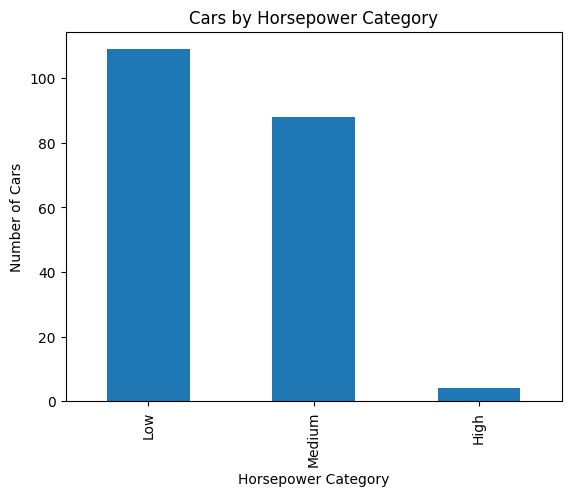

In [29]:
df_clean['horsepower-category'].value_counts().plot(
    kind='bar'
)

plt.xlabel('Horsepower Category')
plt.ylabel('Number of Cars')
plt.title('Cars by Horsepower Category')
plt.show()

In [30]:
print(df_clean['fuel-type'].unique())

print(df_clean['body-style'].unique())

print(df_clean['drive-wheels'].unique())

['gas' 'diesel']
['convertible' 'hatchback' 'sedan' 'wagon' 'hardtop']
['rwd' 'fwd' '4wd']


In [31]:
fuel_encoded = pd.get_dummies(
    df_clean['fuel-type'],
    prefix='fuel'
)

fuel_encoded.head()

,fuel_diesel,fuel_gas
0,False,True
1,False,True
2,False,True
3,False,True
4,False,True


In [32]:
df_encoded = pd.get_dummies(
    df_clean,
    columns=['fuel-type', 'aspiration'],
    dtype=int
)

df_encoded.head()

,symboling,normalized-losses,make,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,horsepower,peak-rpm,city-mpg,highway-mpg,price,horsepower-category,fuel-type_diesel,fuel-type_gas,aspiration_std,aspiration_turbo
0,3,122.0,alfa-romero,two,convertible,rwd,front,88.6,168.8,64.1,...,111.0,5000.0,21,27,13495.0,Medium,0,1,1,0
1,3,122.0,alfa-romero,two,convertible,rwd,front,88.6,168.8,64.1,...,111.0,5000.0,21,27,16500.0,Medium,0,1,1,0
2,1,122.0,alfa-romero,two,hatchback,rwd,front,94.5,171.2,65.5,...,154.0,5000.0,19,26,16500.0,Medium,0,1,1,0
3,2,164.0,audi,four,sedan,fwd,front,99.8,176.6,66.2,...,102.0,5500.0,24,30,13950.0,Medium,0,1,1,0
4,2,164.0,audi,four,sedan,4wd,front,99.4,176.6,66.4,...,115.0,5500.0,18,22,17450.0,Medium,0,1,1,0


In [33]:
df_final = pd.get_dummies(
    df_clean,
    columns=df_clean.select_dtypes(
        include='object'
    ).columns,
    dtype=int
)

print(df_final.shape)
df_final.head()

(201, 76)


,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,...,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_1bbl,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi
0,3,122.0,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,...,0,0,0,0,0,0,0,1,0,0
1,3,122.0,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,...,0,0,0,0,0,0,0,1,0,0
2,1,122.0,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,...,0,0,0,0,0,0,0,1,0,0
3,2,164.0,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,...,0,0,0,0,0,0,0,1,0,0
4,2,164.0,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,...,0,0,0,0,0,0,0,1,0,0


In [34]:
df_final.dtypes

,0
symboling,int64
normalized-losses,float64
wheel-base,float64
length,float64
width,float64
...,...
fuel-system_idi,int64
fuel-system_mfi,int64
fuel-system_mpfi,int64
fuel-system_spdi,int64


In [35]:
df_clean['price'] = pd.to_numeric(df_clean['price'], errors='coerce')

print("Average price:", df_clean['price'].mean())
print("Minimum price:", df_clean['price'].min())
print("Maximum price:", df_clean['price'].max())

df_clean['price'].describe()

Average price: 13207.129353233831
Minimum price: 5118.0
Maximum price: 45400.0


,price
count,201.000000
mean,13207.129353
std,7947.066342
min,5118.000000
25%,7775.000000
50%,10295.000000
75%,16500.000000
max,45400.000000


In [36]:
df_clean['make'].value_counts()

,count
make,
toyota,32
nissan,18
mazda,17
mitsubishi,13
honda,13
subaru,12
volkswagen,12
volvo,11
peugot,11


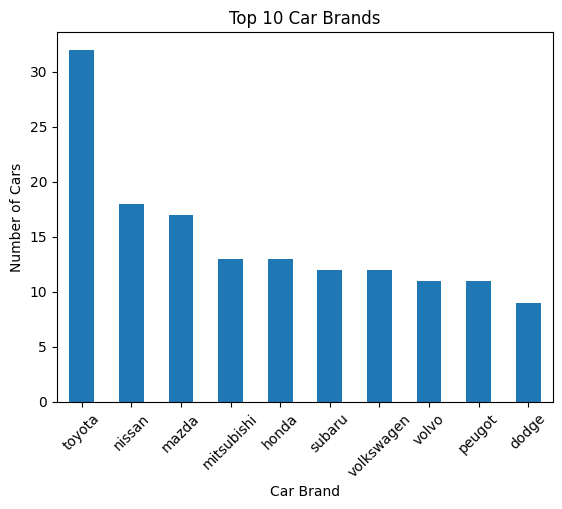

In [37]:
df_clean['make'].value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Car Brands')
plt.xlabel('Car Brand')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)
plt.show()

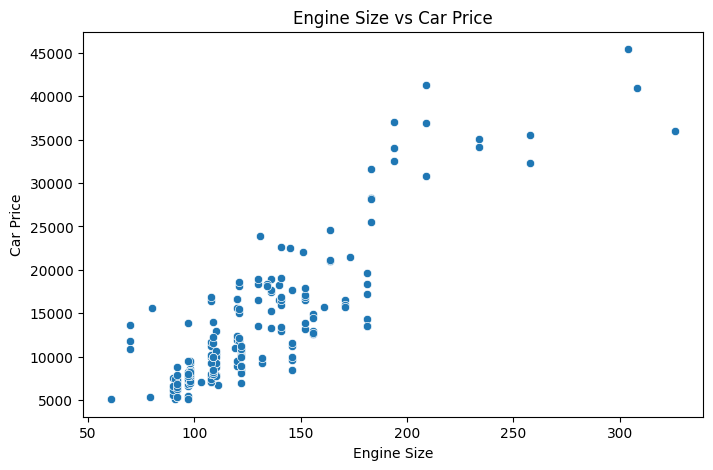

In [38]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x='engine-size',
    y='price'
)

plt.title('Engine Size vs Car Price')
plt.xlabel('Engine Size')
plt.ylabel('Car Price')
plt.show()

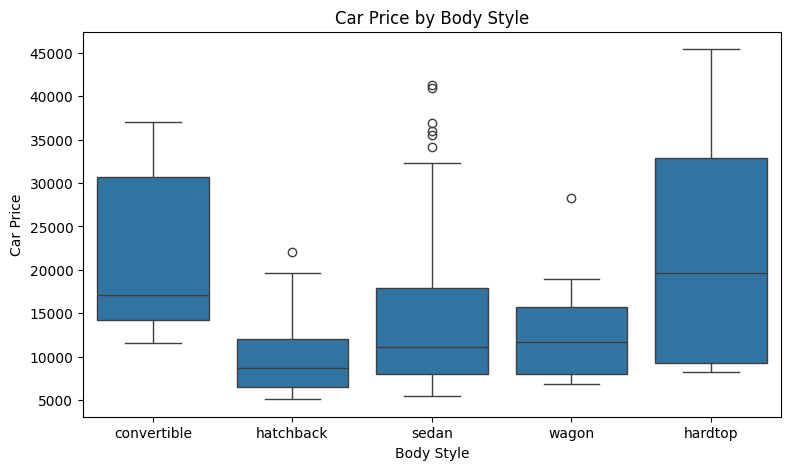

In [39]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='body-style',
    y='price'
)

plt.title('Car Price by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Car Price')
plt.show()

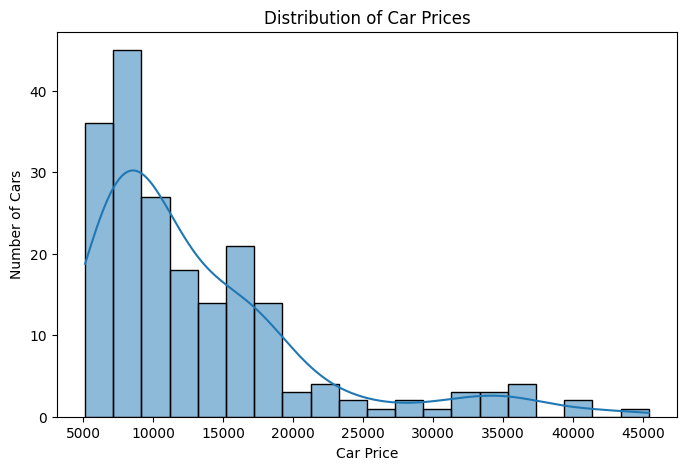

In [40]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x='price',
    bins=20,
    kde=True
)

plt.title('Distribution of Car Prices')
plt.xlabel('Car Price')
plt.ylabel('Number of Cars')
plt.show()

In [41]:
df_clean.groupby('body-style')['price'].mean()

,price
body-style,
convertible,21890.500000
hardtop,22208.500000
hatchback,9957.441176
sedan,14459.755319
wagon,12371.960000


In [42]:
correlation = df_clean.corr(numeric_only=True)

correlation

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
symboling,1.000000,0.466264,-0.535987,-0.365404,-0.242423,-0.550160,-0.233118,-0.110581,-0.139896,-0.007992,-0.182196,0.075790,0.279719,-0.035527,0.036233,-0.082391
normalized-losses,0.466264,1.000000,-0.056661,0.019424,0.086802,-0.373737,0.099404,0.112360,-0.029800,0.055127,-0.114713,0.217300,0.239544,-0.225016,-0.181877,0.133999
wheel-base,-0.535987,-0.056661,1.000000,0.876024,0.814507,0.590742,0.782097,0.572027,0.493203,0.157964,0.250313,0.371250,-0.360233,-0.470606,-0.543304,0.584642
length,-0.365404,0.019424,0.876024,1.000000,0.857170,0.492063,0.880665,0.685025,0.608941,0.123913,0.159733,0.579731,-0.286035,-0.665192,-0.698142,0.690628
width,-0.242423,0.086802,0.814507,0.857170,1.000000,0.306002,0.866201,0.729436,0.544879,0.188814,0.189867,0.615006,-0.245852,-0.633531,-0.680635,0.751265
height,-0.550160,-0.373737,0.590742,0.492063,0.306002,1.000000,0.307581,0.074694,0.180327,-0.060822,0.259737,-0.086941,-0.309913,-0.049800,-0.104812,0.135486
curb-weight,-0.233118,0.099404,0.782097,0.880665,0.866201,0.307581,1.000000,0.849072,0.644041,0.167412,0.156433,0.757994,-0.279350,-0.749543,-0.794889,0.834415
engine-size,-0.110581,0.112360,0.572027,0.685025,0.729436,0.074694,0.849072,1.000000,0.572516,0.205806,0.028889,0.822649,-0.256753,-0.650546,-0.679571,0.872335
bore,-0.139896,-0.029800,0.493203,0.608941,0.544879,0.180327,0.644041,0.572516,1.000000,-0.055390,0.001250,0.566838,-0.267338,-0.582121,-0.591390,0.543154
stroke,-0.007992,0.055127,0.157964,0.123913,0.188814,-0.060822,0.167412,0.205806,-0.055390,1.000000,0.187854,0.097815,-0.063720,-0.034079,-0.034741,0.082267


In [43]:
price_corr = correlation['price'].sort_values(ascending=False)

price_corr

,price
price,1.000000
engine-size,0.872335
curb-weight,0.834415
horsepower,0.809681
width,0.751265
length,0.690628
wheel-base,0.584642
bore,0.543154
height,0.135486
normalized-losses,0.133999


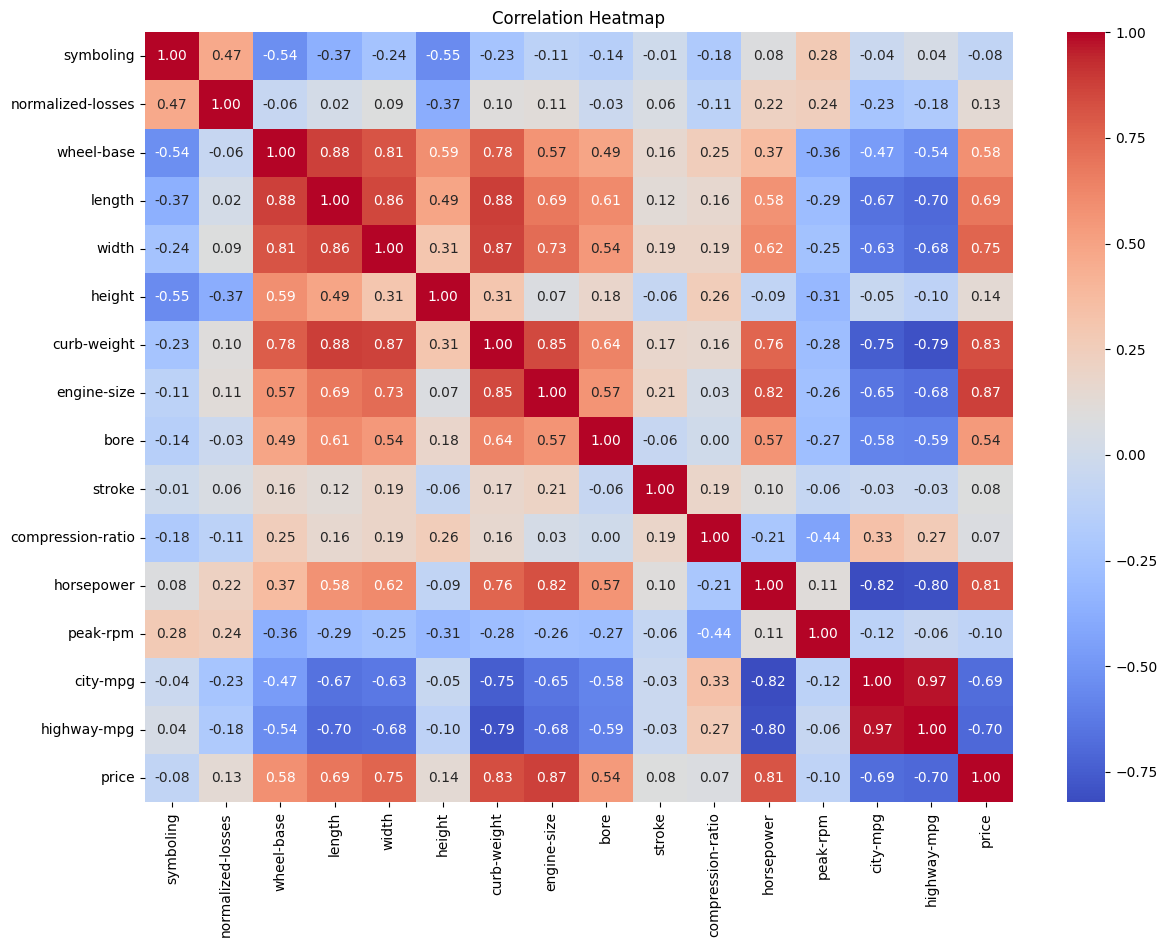

In [44]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [45]:
df_clean.groupby('fuel-type')['price'].mean()

,price
fuel-type,
diesel,15838.15000
gas,12916.40884


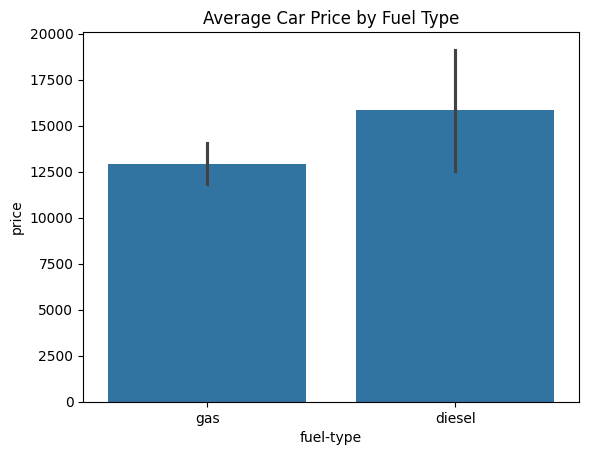

In [46]:
sns.barplot(
    data=df_clean,
    x='fuel-type',
    y='price'
)

plt.title('Average Car Price by Fuel Type')
plt.show()

In [47]:
from scipy.stats import f_oneway

groups = [
    group['price'].dropna()
    for name, group in df_clean.groupby('body-style')
]

f_stat, p_value = f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 9.128751854708211
P-value: 8.779795237614595e-07


In [48]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [49]:
X = df_clean[['engine-size']]
y = df_clean['price']

print(X.head())
print(y.head())

   engine-size
0          130
1          130
2          152
3          109
4          136
0    13495.0
1    16500.0
2    16500.0
3    13950.0
4    17450.0
Name: price, dtype: float64


In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 1)
Testing data: (41, 1)


In [51]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [52]:
predictions = model.predict(X_test)

print("Predicted prices:")
print(predictions[:10])

print("Actual prices:")
print(y_test.head(10).values)

Predicted prices:
[ 8468.83905442 25073.52802615  7727.55829675  8617.09520595
 12026.98669122  7431.04599369 28779.93181449 12175.24284275
 19439.79426789 32338.07945128]
Actual prices:
[ 8249. 41315.  6855.  9258. 11850.  5572. 35056.  9988. 15998. 35550.]


In [53]:
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Squared Error: 33696986.98421676
R2 Score: 0.724578048646674


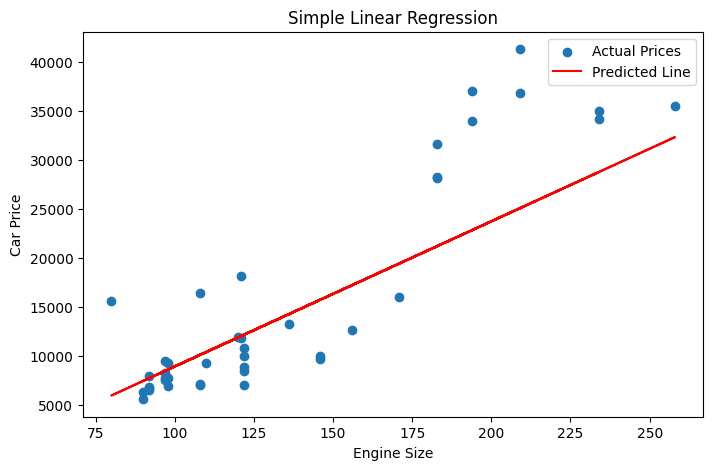

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test, y_test, label='Actual Prices')
plt.plot(X_test, predictions, color='red', label='Predicted Line')

plt.xlabel('Engine Size')
plt.ylabel('Car Price')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

In [55]:
new_car = pd.DataFrame({'engine-size': [150]})

predicted_price = model.predict(new_car)

print("Predicted car price:", predicted_price[0])

Predicted car price: 16326.415085686998


In [56]:
features = [
    'engine-size',
    'horsepower',
    'highway-mpg',
    'curb-weight'
]

X = df_clean[features]
y = df_clean['price']

print(X.head())
print(y.head())

   engine-size  horsepower  highway-mpg  curb-weight
0          130       111.0           27         2548
1          130       111.0           27         2548
2          152       154.0           26         2823
3          109       102.0           30         2337
4          136       115.0           22         2824
0    13495.0
1    16500.0
2    16500.0
3    13950.0
4    17450.0
Name: price, dtype: float64


In [57]:
X = X.apply(pd.to_numeric, errors='coerce')

data = pd.concat([X, y], axis=1).dropna()

X = data[features]
y = data['price']

print("Missing values:", X.isnull().sum().sum())

Missing values: 0


In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (160, 4)
Testing: (41, 4)


In [59]:
from sklearn.linear_model import LinearRegression

multi_model = LinearRegression()

multi_model.fit(X_train, y_train)

print("Multiple Linear Regression trained!")

Multiple Linear Regression trained!


In [60]:
predictions = multi_model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': predictions
})

comparison.head(10)

,Actual Price,Predicted Price
0,8249.0,6999.550837
1,41315.0,25416.248682
2,6855.0,5987.280110
3,9258.0,7803.489708
4,11850.0,13107.135879
5,5572.0,5790.573119
6,35056.0,28202.488565
7,9988.0,11537.259937
8,15998.0,20205.452602
9,35550.0,32118.554770


In [61]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("MSE:", mse)
print("R2 Score:", r2)

MSE: 28904157.947639566
R2 Score: 0.7637521839002284


In [62]:
print("Simple Linear Regression R2:", r2_score(y_test, model.predict(X_test[['engine-size']])))
print("Multiple Linear Regression R2:", r2)

Simple Linear Regression R2: 0.724578048646674
Multiple Linear Regression R2: 0.7637521839002284


In [63]:
new_car = pd.DataFrame({
    'engine-size': [150],
    'horsepower': [120],
    'highway-mpg': [30],
    'curb-weight': [2500]
})

predicted_price = multi_model.predict(new_car)

print("Estimated Car Price:", predicted_price[0])

Estimated Car Price: 15049.419335335222


In [64]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions = multi_model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3768.4112016095924
MSE: 28904157.947639566
RMSE: 5376.25873146369
R2 Score: 0.7637521839002284


In [65]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': predictions
})

comparison['Difference'] = (
    comparison['Actual Price'] - comparison['Predicted Price']
)

comparison.head(10)

,Actual Price,Predicted Price,Difference
98,8249.0,6999.550837,1249.449163
16,41315.0,25416.248682,15898.751318
31,6855.0,5987.280110,867.719890
162,9258.0,7803.489708,1454.510292
132,11850.0,13107.135879,-1257.135879
118,5572.0,5790.573119,-218.573119
72,35056.0,28202.488565,6853.511435
175,9988.0,11537.259937,-1549.259937
179,15998.0,20205.452602,-4207.452602
48,35550.0,32118.554770,3431.445230


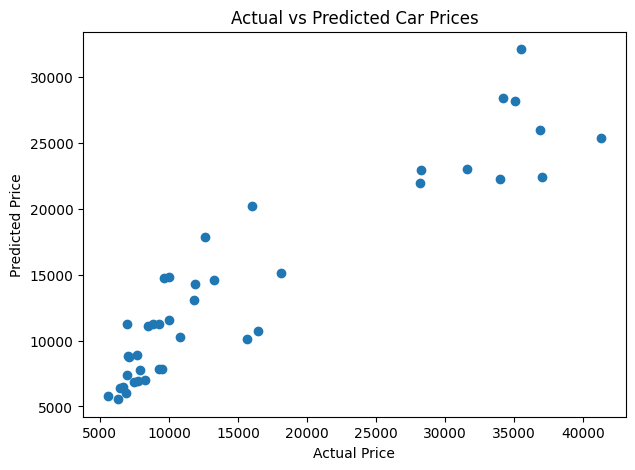

In [66]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions)

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Car Prices')

plt.show()

In [67]:
residuals = y_test - predictions

print(residuals.head(10))

98      1249.449163
16     15898.751318
31       867.719890
162     1454.510292
132    -1257.135879
118     -218.573119
72      6853.511435
175    -1549.259937
179    -4207.452602
48      3431.445230
Name: price, dtype: float64


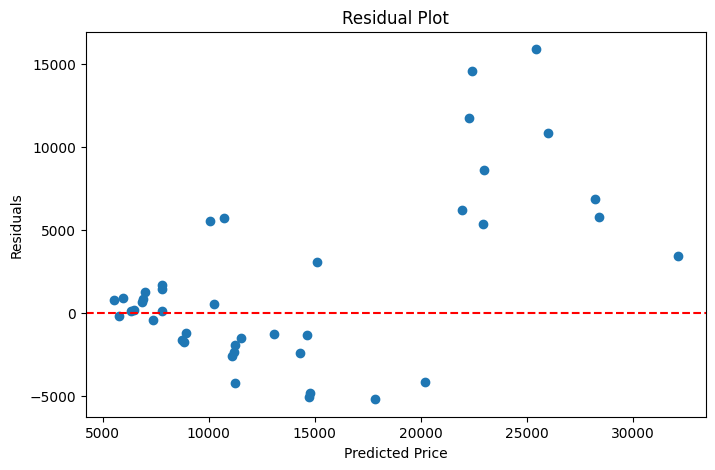

In [68]:
plt.figure(figsize=(8, 5))

plt.scatter(predictions, residuals)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Price')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.show()

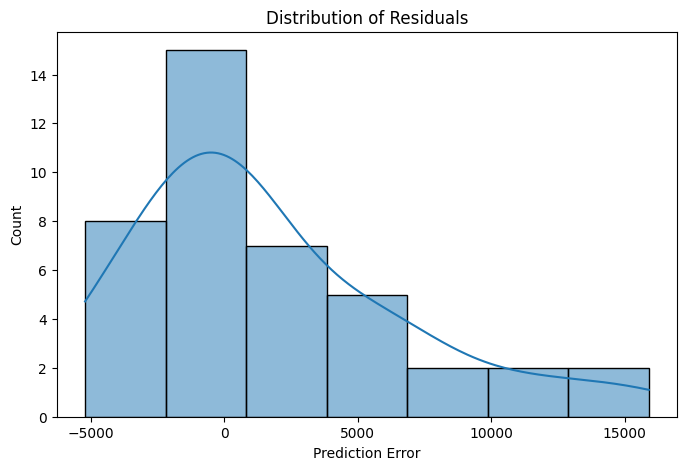

In [69]:
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title('Distribution of Residuals')
plt.xlabel('Prediction Error')
plt.show()

In [70]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [71]:
X = df_clean[['engine-size']]
y = df_clean['price']

data = pd.concat([X, y], axis=1).dropna()

X = data[['engine-size']]
y = data['price']

In [72]:
poly = PolynomialFeatures(degree=2)

X_poly = poly.fit_transform(X)

print("Original shape:", X.shape)
print("Polynomial shape:", X_poly.shape)

Original shape: (201, 1)
Polynomial shape: (201, 3)


In [73]:
poly_model = LinearRegression()

poly_model.fit(X_poly, y)

print("Polynomial model trained!")

Polynomial model trained!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


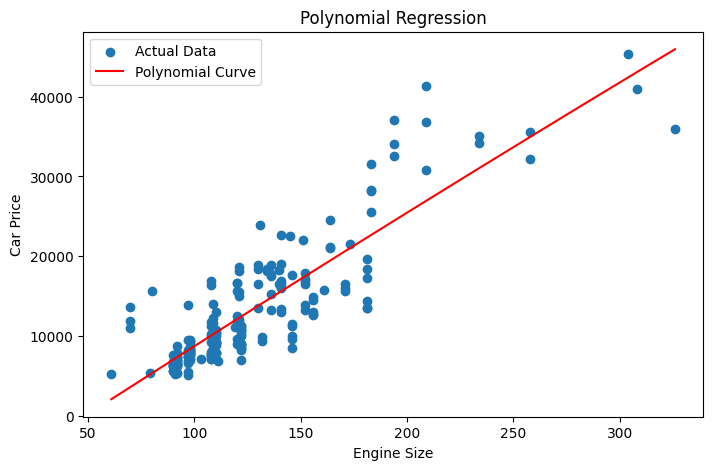

In [74]:
X_range = np.linspace(
    X['engine-size'].min(),
    X['engine-size'].max(),
    200
).reshape(-1, 1)

X_range_poly = poly.transform(X_range)

y_curve = poly_model.predict(X_range_poly)

plt.figure(figsize=(8, 5))

plt.scatter(X['engine-size'], y, label='Actual Data')
plt.plot(X_range, y_curve, color='red', label='Polynomial Curve')

plt.xlabel('Engine Size')
plt.ylabel('Car Price')
plt.title('Polynomial Regression')
plt.legend()
plt.show()

In [75]:
poly_predictions = poly_model.predict(X_poly)

print("R2 Score:", r2_score(y, poly_predictions))
print("MSE:", mean_squared_error(y, poly_predictions))

R2 Score: 0.7610415105095263
MSE: 15016546.995870547


In [76]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [77]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
    ('regression', LinearRegression())
])

In [78]:
features = [
    'engine-size',
    'horsepower',
    'highway-mpg',
    'curb-weight'
]

X = df_clean[features].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(df_clean['price'], errors='coerce')

data = pd.concat([X, y.rename('price')], axis=1).dropna()

X = data[features]
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

pipeline.fit(X_train, y_train)

print("Pipeline trained successfully!")

Pipeline trained successfully!


In [79]:
pipeline_predictions = pipeline.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pipeline_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pipeline_predictions)))
print("R2 Score:", r2_score(y_test, pipeline_predictions))

MAE: 3768.4112016095905
RMSE: 5376.258731463687
R2 Score: 0.7637521839002288


In [80]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [81]:
features = [
    'engine-size',
    'horsepower',
    'highway-mpg',
    'curb-weight'
]

X = df_clean[features].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(df_clean['price'], errors='coerce')

data = pd.concat([X, y.rename('price')], axis=1).dropna()

X = data[features]
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [82]:
linear_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

linear_pipeline.fit(X_train, y_train)

linear_predictions = linear_pipeline.predict(X_test)

print("Linear R2:", r2_score(y_test, linear_predictions))
print("Linear MSE:", mean_squared_error(y_test, linear_predictions))

Linear R2: 0.7637521839002288
Linear MSE: 28904157.947639525


In [83]:
ridge_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_train, y_train)

ridge_predictions = ridge_pipeline.predict(X_test)

print("Ridge R2:", r2_score(y_test, ridge_predictions))
print("Ridge MSE:", mean_squared_error(y_test, ridge_predictions))

Ridge R2: 0.7630083110064989
Ridge MSE: 28995168.395771056


In [84]:
from sklearn.model_selection import GridSearchCV

ridge_search_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

parameters = {
    'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]
}

grid_search = GridSearchCV(
    ridge_search_pipeline,
    parameters,
    cv=5,
    scoring='r2'
)

grid_search.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('model', Ridge())]),
             param_grid={'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
             scoring='r2')

In [85]:
print("Best Alpha:", grid_search.best_params_)
print("Best Cross-Validation R2:", grid_search.best_score_)

Best Alpha: {'model__alpha': 10}
Best Cross-Validation R2: 0.7622139441698152


In [86]:
best_model = grid_search.best_estimator_

best_predictions = best_model.predict(X_test)

print("Final Test R2:", r2_score(y_test, best_predictions))
print("Final Test MSE:", mean_squared_error(y_test, best_predictions))
print("Final Test MAE:", mean_absolute_error(y_test, best_predictions))

Final Test R2: 0.7550485634695118
Final Test MSE: 29969017.821474306
Final Test MAE: 3837.0099224487394


In [87]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split

features = [
    'engine-size',
    'horsepower',
    'highway-mpg',
    'curb-weight'
]

X = df_clean[features].apply(pd.to_numeric, errors='coerce')
y = pd.to_numeric(df_clean['price'], errors='coerce')

data = pd.concat([X, y.rename('price')], axis=1).dropna()

X = data[features]
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [88]:
models = {
    'Simple Linear': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Multiple Linear': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Polynomial': Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),

    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0))
    ])
}

In [89]:
results = []

for name, model in models.items():

    if name == 'Simple Linear':
        train_X = X_train[['engine-size']]
        test_X = X_test[['engine-size']]
    else:
        train_X = X_train
        test_X = X_test

    model.fit(train_X, y_train)

    train_predictions = model.predict(train_X)
    test_predictions = model.predict(test_X)

    results.append({
        'Model': name,
        'Training R2': r2_score(y_train, train_predictions),
        'Testing R2': r2_score(y_test, test_predictions),
        'Testing MSE': mean_squared_error(y_test, test_predictions)
    })

results_df = pd.DataFrame(results)
results_df

,Model,Training R2,Testing R2,Testing MSE
0,Simple Linear,0.756671,0.724578,3.369699e+07
1,Multiple Linear,0.808929,0.763752,2.890416e+07
2,Polynomial,0.852652,0.756108,2.983934e+07
3,Ridge,0.808912,0.763008,2.899517e+07


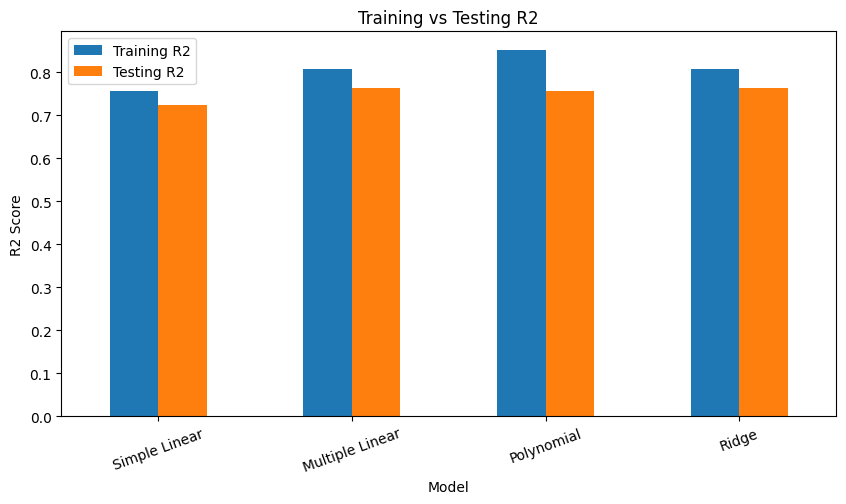

In [90]:
results_df.plot(
    x='Model',
    y=['Training R2', 'Testing R2'],
    kind='bar',
    figsize=(10, 5)
)

plt.title('Training vs Testing R2')
plt.ylabel('R2 Score')
plt.xticks(rotation=20)
plt.show()

In [91]:
best_model_name = results_df.loc[
    results_df['Testing R2'].idxmax(),
    'Model'
]

print("Best model:", best_model_name)

Best model: Multiple Linear


In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [93]:
features = [
    'engine-size',
    'horsepower',
    'highway-mpg',
    'curb-weight',
    'make',
    'fuel-type',
    'body-style',
    'drive-wheels'
]

X = df[features].copy()
y = pd.to_numeric(df['price'], errors='coerce')

# Convert numerical columns into numeric format
numeric_features = [
    'engine-size',
    'horsepower',
    'highway-mpg',
    'curb-weight'
]

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Remove rows where target price is missing
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (201, 8)
Target shape: (201,)


In [94]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 160
Testing records: 41


In [95]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [96]:
preprocessor = ColumnTransformer([
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer,
     ['make', 'fuel-type', 'body-style', 'drive-wheels'])
])

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

In [97]:
parameters = {
    'model__alpha': [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    final_pipeline,
    parameters,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV R2:", grid_search.best_score_)

Best parameters: {'model__alpha': 1}
Best CV R2: 0.8543330841603158


In [98]:
best_model = grid_search.best_estimator_

final_predictions = best_model.predict(X_test)

mae = mean_absolute_error(y_test, final_predictions)
mse = mean_squared_error(y_test, final_predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, final_predictions)

print("Final Model Evaluation")
print("----------------------")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Final Model Evaluation
----------------------
MAE: 2286.641545839152
MSE: 12012613.858895713
RMSE: 3465.9217906490207
R2 Score: 0.9018150331535356


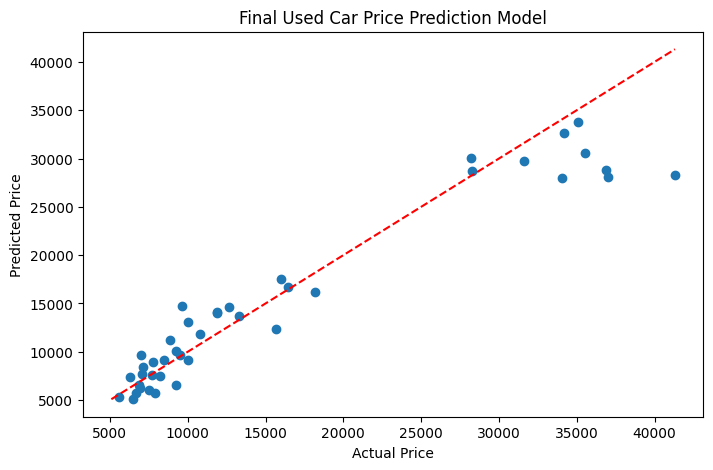

In [99]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, final_predictions)

min_price = min(y_test.min(), final_predictions.min())
max_price = max(y_test.max(), final_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--'
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Final Used Car Price Prediction Model")
plt.show()

In [100]:
new_car = pd.DataFrame({
    'engine-size': [150],
    'horsepower': [120],
    'highway-mpg': [30],
    'curb-weight': [2500],
    'make': ['toyota'],
    'fuel-type': ['gas'],
    'body-style': ['sedan'],
    'drive-wheels': ['fwd']
})

predicted_price = best_model.predict(new_car)

print("Estimated Used Car Price:", predicted_price[0])

Estimated Used Car Price: 12219.255126954688


In [101]:
joblib.dump(best_model, 'used_car_price_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [102]:
from google.colab import files

files.download('used_car_price_model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [103]:
from google.colab import files

uploaded = files.upload()

Saving used_car_price_model.pkl to used_car_price_model (1).pkl


In [104]:
print(uploaded.keys())

dict_keys(['used_car_price_model (1).pkl'])


In [105]:
import joblib

model = joblib.load('used_car_price_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [106]:
import pandas as pd

new_car = pd.DataFrame({
    'engine-size': [150],
    'horsepower': [120],
    'highway-mpg': [30],
    'curb-weight': [2500],
    'make': ['toyota'],
    'fuel-type': ['gas'],
    'body-style': ['sedan'],
    'drive-wheels': ['fwd']
})

prediction = model.predict(new_car)

print("Predicted Car Price:", prediction[0])

Predicted Car Price: 12219.255126954688


In [107]:
print(uploaded.keys())

dict_keys(['used_car_price_model (1).pkl'])


In [108]:
import joblib

model = joblib.load('used_car_price_model.pkl')

print("Model loaded successfully!")

Model loaded successfully!


In [109]:
import pandas as pd

new_car = pd.DataFrame({
    'engine-size': [150],
    'horsepower': [120],
    'highway-mpg': [30],
    'curb-weight': [2500],
    'make': ['toyota'],
    'fuel-type': ['gas'],
    'body-style': ['sedan'],
    'drive-wheels': ['fwd']
})

prediction = model.predict(new_car)

print("Predicted Car Price:", prediction[0])

Predicted Car Price: 12219.255126954688


In [110]:
import sklearn

print(sklearn.__version__)

1.6.1
